In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

SEQUENCE_LENGTH = 24
BATCH_SIZE = 32

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [3]:
csv_path = "../data/PRSA_Data_Aotizhongxin_20130301-20170228.csv"

df = pd.read_csv(csv_path)
df["timestamp"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("timestamp").reset_index(drop=True)

assert df["timestamp"].is_monotonic_increasing
assert not df["timestamp"].duplicated().any()

print("Ham veri:", df.shape)
print("Eksik PM2.5:", df["PM2.5"].isna().sum())

Ham veri: (35064, 19)
Eksik PM2.5: 925


In [4]:
def create_sequences(dataframe, sequence_length=24):
    ordered = dataframe.sort_values("timestamp").reset_index(drop=True)
    X_list, y_list, target_time_list = [], [], []

    for i in range(len(ordered) - sequence_length):
        x_window = ordered["PM2.5"].iloc[i:i + sequence_length]
        y_next = ordered["PM2.5"].iloc[i + sequence_length]

        if x_window.isna().any() or pd.isna(y_next):
            continue

        # 24 giriş zamanı + 1 hedef zamanı
        times = ordered["timestamp"].iloc[i:i + sequence_length + 1]
        if not (times.diff().dropna() == pd.Timedelta(hours=1)).all():
            continue

        X_list.append(x_window.to_numpy().reshape(sequence_length, 1))
        y_list.append(y_next)
        target_time_list.append(times.iloc[-1])

    X_array = np.asarray(X_list, dtype=np.float32).reshape(-1, sequence_length, 1)
    y_array = np.asarray(y_list, dtype=np.float32)
    target_times = pd.DatetimeIndex(target_time_list)
    return X_array, y_array, target_times


X, y, target_times = create_sequences(df, sequence_length=SEQUENCE_LENGTH)

print("X:", X.shape)
print("y:", y.shape)
print("Hedef saatleri:", len(target_times))
assert X.ndim == 3 and X.shape[1:] == (24, 1)
assert len(X) == len(y) == len(target_times)

X: (30062, 24, 1)
y: (30062,)
Hedef saatleri: 30062


In [5]:
n = len(df)
val_start_time = df.loc[int(n * 0.70), "timestamp"]
test_start_time = df.loc[int(n * 0.85), "timestamp"]

train_mask = target_times < val_start_time
val_mask = (target_times >= val_start_time) & (target_times < test_start_time)

X_train_seq, y_train_seq = X[train_mask], y[train_mask]
X_val_seq, y_val_seq = X[val_mask], y[val_mask]

print("Validation başlangıcı:", val_start_time)
print("Test başlangıcı:", test_start_time)
print("Train:", X_train_seq.shape, y_train_seq.shape)
print("Validation:", X_val_seq.shape, y_val_seq.shape)

assert target_times[train_mask].max() < target_times[val_mask].min()
assert X_train_seq.shape[1:] == X_val_seq.shape[1:] == (24, 1)

Validation başlangıcı: 2015-12-18 16:00:00
Test başlangıcı: 2016-07-24 20:00:00
Train: (21177, 24, 1) (21177,)
Validation: (4266, 24, 1) (4266,)


In [6]:
input_scaler = StandardScaler()
target_scaler = StandardScaler()

X_train_scaled = input_scaler.fit_transform(
    X_train_seq.reshape(-1, 1)
).reshape(X_train_seq.shape)

X_val_scaled = input_scaler.transform(
    X_val_seq.reshape(-1, 1)
).reshape(X_val_seq.shape)

y_train_scaled = target_scaler.fit_transform(y_train_seq.reshape(-1, 1))
y_val_scaled = target_scaler.transform(y_val_seq.reshape(-1, 1))

print("X train:", X_train_scaled.shape)
print("X val:", X_val_scaled.shape)
print("y train:", y_train_scaled.shape)
print("y val:", y_val_scaled.shape)

X train: (21177, 24, 1)
X val: (4266, 24, 1)
y train: (21177, 1)
y val: (4266, 1)


In [7]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

X_batch, y_batch = next(iter(train_loader))
print("Batch X:", X_batch.shape)
print("Batch y:", y_batch.shape)

assert X_batch.shape[1:] == (24, 1)
assert y_batch.shape[1] == 1

Batch X: torch.Size([32, 24, 1])
Batch y: torch.Size([32, 1])


In [8]:
class AirPulseLSTM(nn.Module):

    def __init__(self, input_size=1, hidden_size=32):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size , 
            hidden_size=hidden_size,
            batch_first=True,
            num_layers=1
        )

        self.fc = nn.Linear(32,1)

    def forward(self, x):

        out , (hidden , cell) = self.lstm(x)

        # LSTM forward pass

        # Son hidden state
        last_hidden = hidden[-1]

        # PM2.5 tahmini
        prediction = self.fc(last_hidden)

        return prediction

In [9]:
sample = torch.randn(32, 24, 1)

model = AirPulseLSTM()

output, (hidden, cell) = model.lstm(sample)

prediction = model(sample)

print("Input:", sample.shape)
print("Output:", output.shape)
print("Hidden State:", hidden.shape)
print("Cell State:", cell.shape)
print("Final Prediction:", prediction.shape)

Input: torch.Size([32, 24, 1])
Output: torch.Size([32, 24, 32])
Hidden State: torch.Size([1, 32, 32])
Cell State: torch.Size([1, 32, 32])
Final Prediction: torch.Size([32, 1])


In [10]:
torch.manual_seed(42)

model = AirPulseLSTM()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10

In [11]:
def train_model(model, train_loader, val_loader,
                optimizer, criterion, epochs=10):

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0

        for X_batch , y_batch in train_loader:

            optimizer.zero_grad()
            prediction = model(X_batch)
            loss = criterion(prediction , y_batch)

            loss.backward()

            optimizer.step()

            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)


        model.eval()
        total_val_loss = 0.0

        with torch.no_grad():


            for X_batch , y_batch in val_loader:

                prediction = model(X_batch)

                loss = criterion(prediction , y_batch)

                total_val_loss += loss.item()


        avg_val_loss = total_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        # RESULTS
        print(f"Epoch {epoch + 1}/{epochs}")
        print(f"Train Loss: {avg_train_loss:.4f}")
        print(f"Validation Loss: {avg_val_loss:.4f}")
        print()
        
    return train_losses, val_losses


In [12]:
train_losses, val_losses = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    epochs=10
)

Epoch 1/10
Train Loss: 0.2456
Validation Loss: 0.1635

Epoch 2/10
Train Loss: 0.0759
Validation Loss: 0.1006

Epoch 3/10
Train Loss: 0.0621
Validation Loss: 0.0855

Epoch 4/10
Train Loss: 0.0603
Validation Loss: 0.0819

Epoch 5/10
Train Loss: 0.0600
Validation Loss: 0.0798

Epoch 6/10
Train Loss: 0.0597
Validation Loss: 0.0781

Epoch 7/10
Train Loss: 0.0594
Validation Loss: 0.0767

Epoch 8/10
Train Loss: 0.0592
Validation Loss: 0.0755

Epoch 9/10
Train Loss: 0.0590
Validation Loss: 0.0746

Epoch 10/10
Train Loss: 0.0589
Validation Loss: 0.0739



In [13]:
model.eval()

predictions_scaled = []

with torch.no_grad():

    for X_batch, y_batch in val_loader:

        predictions = model(X_batch)

        predictions_scaled.append(
            predictions.cpu().numpy()
        )

predictions_scaled = np.concatenate(predictions_scaled)

predictions_original = target_scaler.inverse_transform(
    predictions_scaled
)


lstm_mae = mean_absolute_error(
    y_val_seq,
    predictions_original.ravel()
)


lstm_rmse = np.sqrt(
    mean_squared_error(
        y_val_seq,
        predictions_original.ravel()
    )
)


results = pd.DataFrame({
    "Metrik": [
        "Final Training Loss",
        "Final Validation Loss",
        "Validation MAE",
        "Validation RMSE"
    ],
    "LSTM": [
        train_losses[-1],
        val_losses[-1],
        lstm_mae,
        lstm_rmse
    ]
})

display(results.round(4))

,Metrik,LSTM
0,Final Training Loss,0.0589
1,Final Validation Loss,0.0739
2,Validation MAE,10.4699
3,Validation RMSE,20.7776


In [14]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(exist_ok=True)

np.savez(
    reports_dir / "rnn_validation_reference.npz",
    target_times=target_times[val_mask].to_numpy(),
    y_true=y_val_seq
)

print("RNN validation örneği:", len(y_val_seq))

RNN validation örneği: 4266


In [15]:

reference = np.load("../reports/rnn_validation_reference.npz")

rnn_times = reference["target_times"]
rnn_y = reference["y_true"]

lstm_times = target_times[val_mask].to_numpy()
lstm_y = y_val_seq

# 1. Örnek sayısı
assert len(lstm_times) == 4266
assert len(rnn_times) == len(lstm_times)
assert predictions_original.shape[0] == 4266

# 2. Aynı hedef zamanları ve aynı sıra
assert np.array_equal(rnn_times, lstm_times)

# 3. Aynı gerçek değerler
assert np.allclose(rnn_y, lstm_y)

print("✅ Validation örnek sayısı: 4266")
print("✅ RNN ve LSTM hedef zamanları aynı")
print("✅ Hedef zamanlarının sıralaması aynı")
print("✅ Gerçek PM2.5 değerleri aynı")

✅ Validation örnek sayısı: 4266
✅ RNN ve LSTM hedef zamanları aynı
✅ Hedef zamanlarının sıralaması aynı
✅ Gerçek PM2.5 değerleri aynı


In [16]:
naive_predictions = X_val_seq[:, -1, 0]

naive_mae = mean_absolute_error(y_val_seq, naive_predictions)
naive_rmse = np.sqrt(
    mean_squared_error(y_val_seq, naive_predictions)
)

print(f"Naive MAE: {naive_mae:.2f}")
print(f"Naive RMSE: {naive_rmse:.2f}")

Naive MAE: 10.37
Naive RMSE: 21.59


In [17]:
comparison_df = pd.DataFrame({
    "Model": [
        "Naive Forecast",
        "RNN",
        "LSTM"
    ],
    "Validation MAE": [
        10.37,
        10.66,
        lstm_mae
    ],
    "Validation RMSE": [
        21.59,
        21.14,
        lstm_rmse
    ]
})

display(
    comparison_df.style
    .format({
        "Validation MAE": "{:.2f}",
        "Validation RMSE": "{:.2f}"
    })
    .highlight_min(
        subset=["Validation MAE", "Validation RMSE"],
        color="lightgreen"
    )
    .hide(axis="index")
)

Model,Validation MAE,Validation RMSE
Naive Forecast,10.37,21.59
RNN,10.66,21.14
LSTM,10.47,20.78


In [18]:
val_target_times = target_times[val_mask]


lstm_predictions = predictions_original.ravel()


assert len(val_target_times) == len(y_val_seq) == len(lstm_predictions)


error_df = pd.DataFrame({
    "Target Timestamp": val_target_times,
    "Gerçek PM2.5": y_val_seq,
    "LSTM Tahmini": lstm_predictions
})


error_df["Mutlak Hata"] = abs(
    error_df["Gerçek PM2.5"] - error_df["LSTM Tahmini"]
)

# En büyük 5 hata
top5_errors = error_df.nlargest(5, "Mutlak Hata")

display(top5_errors.round(2))

/tmp/ipykernel_18116/3964617588.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(top5_errors.round(2))


,Target Timestamp,Gerçek PM2.5,LSTM Tahmini,Mutlak Hata
1053,2016-02-08 02:00:00,898.0,408.130005,489.869995
1052,2016-02-08 01:00:00,494.0,171.490005,322.510010
121,2015-12-24 22:00:00,312.0,47.910000,264.089996
1683,2016-03-09 14:00:00,270.0,15.790000,254.210007
1060,2016-02-08 09:00:00,37.0,275.390015,238.389999


In [19]:
for idx in top5_errors.index:

    # Önceki 24 saatlik PM2.5 ölçümleri
    past_24h = X_val_seq[idx, :, 0]

    # Gerçek ve tahmin
    actual = y_val_seq[idx]
    predicted = lstm_predictions[idx]

    print("=" * 50)
    print("Hedef zamanı:", val_target_times[idx])

    print("24 saat önce:", past_24h[0])
    print("Son gözlem:", past_24h[-1])

    print("Gerçek PM2.5:", actual)
    print("LSTM Tahmini:", round(float(predicted), 2))

    print("Son saatlik değişim:", actual - past_24h[-1])

    print("Geçmiş 24 saat:")
    print(np.round(past_24h, 1))

Hedef zamanı: 2016-02-08 02:00:00
24 saat önce: 48.0
Son gözlem: 494.0
Gerçek PM2.5: 898.0
LSTM Tahmini: 408.13
Son saatlik değişim: 404.0
Geçmiş 24 saat:
[ 48.  47.  51.  58.  41.  40.  41.  43.  42.  33.  22.  17.  13.  19.
  24.  23.  21.  16.  32.  38.  44.  61. 152. 494.]
Hedef zamanı: 2016-02-08 01:00:00
24 saat önce: 48.0
Son gözlem: 152.0
Gerçek PM2.5: 494.0
LSTM Tahmini: 171.49
Son saatlik değişim: 342.0
Geçmiş 24 saat:
[ 48.  48.  47.  51.  58.  41.  40.  41.  43.  42.  33.  22.  17.  13.
  19.  24.  23.  21.  16.  32.  38.  44.  61. 152.]
Hedef zamanı: 2015-12-24 22:00:00
24 saat önce: 154.0
Son gözlem: 44.0
Gerçek PM2.5: 312.0
LSTM Tahmini: 47.91
Son saatlik değişim: 268.0
Geçmiş 24 saat:
[154. 162. 136.  97.  91.  70.  49.  37.  33.  34.  37.  42.  47.  53.
  77.  59.  32.  35.  35.  31.  37.  42.  46.  44.]
Hedef zamanı: 2016-03-09 14:00:00
24 saat önce: 15.0
Son gözlem: 23.0
Gerçek PM2.5: 270.0
LSTM Tahmini: 15.79
Son saatlik değişim: 247.0
Geçmiş 24 saat:
[15. 20. 26. 3

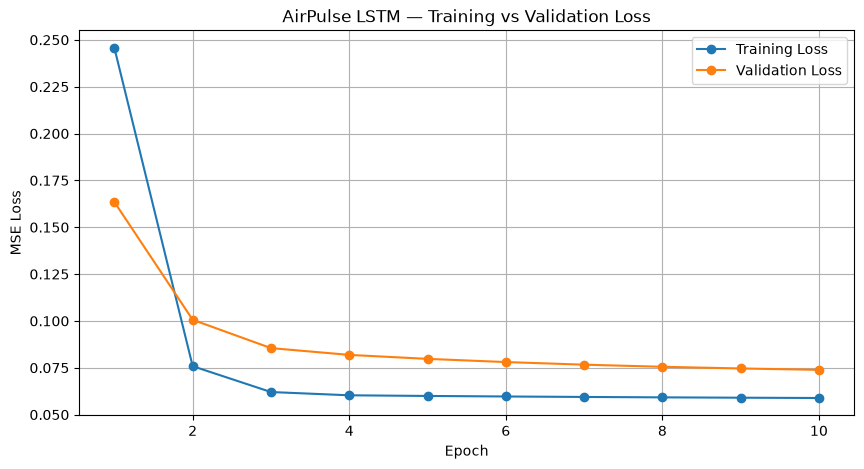

In [20]:
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label="Training Loss",
    marker="o"
)

plt.plot(
    epochs_range,
    val_losses,
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("AirPulse LSTM — Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [21]:
rnn_times = target_times[val_mask]


rnn_predictions = predictions_original.ravel()


assert len(rnn_times) == len(rnn_predictions) == 4266


np.savez(
    "../reports/rnn_predictions.npz",
    timestamps=rnn_times.to_numpy(),
    predictions=rnn_predictions,
    actual=y_val_seq
)

print("✅ RNN tahminleri kaydedildi.")
print("Örnek sayısı:", len(rnn_predictions))

✅ RNN tahminleri kaydedildi.
Örnek sayısı: 4266


In [22]:
# TEST 1 — LSTM Tensor Shape

# Tensor 3 boyutlu mu?
assert X_train_tensor.ndim == 3

# Sequence length 24 mü?
assert X_train_tensor.shape[1] == 24

# Input size 1 mi?
assert X_train_tensor.shape[2] == 1

print("✅ Test 1 PASSED — Tensor boyutları doğru.")

✅ Test 1 PASSED — Tensor boyutları doğru.


In [23]:
# TEST 2 — LSTM Model Output

# Validation verisinden bir batch al
X_batch, y_batch = next(iter(val_loader))

# Modeli değerlendirme moduna al
model.eval()

# Tahmin üret
with torch.no_grad():
    predictions = model(X_batch)

# Boyutları kontrol et
assert X_batch.shape == (32, 24, 1)
assert predictions.shape == (32, 1)

print("Input Shape:", X_batch.shape)
print("Output Shape:", predictions.shape)
print("✅ Test 2 PASSED — LSTM output boyutları doğru.")

Input Shape: torch.Size([32, 24, 1])
Output Shape: torch.Size([32, 1])
✅ Test 2 PASSED — LSTM output boyutları doğru.


In [24]:
# TEST 3 — Data Leakage

import numpy as np

# 1. Training ve Validation hedef zamanları
train_target_times = target_times[train_mask]
val_target_times = target_times[val_mask]

assert train_target_times.max() < val_target_times.min()

print("✅ Temporal Split doğru.")


# 2. Input Scaler kontrolü
train_input = X_train_seq.reshape(-1, 1)

assert np.allclose(
    input_scaler.mean_,
    train_input.mean(axis=0)
)

assert input_scaler.n_samples_seen_ == len(train_input)

print("✅ Input Scaler training istatistikleri doğru.")


# 3. Target Scaler kontrolü
train_target = y_train_seq.reshape(-1, 1)

assert np.allclose(
    target_scaler.mean_,
    train_target.mean(axis=0)
)

assert target_scaler.n_samples_seen_ == len(train_target)

print("✅ Target Scaler training istatistikleri doğru.")


# 4. Validation transform kontrolü
assert np.allclose(
    X_val_scaled,
    input_scaler.transform(
        X_val_seq.reshape(-1, 1)
    ).reshape(X_val_seq.shape)
)

assert np.allclose(
    y_val_scaled,
    target_scaler.transform(
        y_val_seq.reshape(-1, 1)
    )
)

print("✅ Validation normalizasyonu doğru.")

print("\n✅ TEST 3 PASSED")

✅ Temporal Split doğru.
✅ Input Scaler training istatistikleri doğru.
✅ Target Scaler training istatistikleri doğru.
✅ Validation normalizasyonu doğru.

✅ TEST 3 PASSED


In [25]:
# RNN sonuçlarını yükle
rnn_data = np.load("../reports/rnn_predictions.npz")

rnn_times = rnn_data["timestamps"]
rnn_actual = rnn_data["actual"]
rnn_predictions = rnn_data["predictions"]

# LSTM validation bilgileri
lstm_times = target_times[val_mask].to_numpy()

# Aynı örnekleri kullandığımızı doğrula
assert len(lstm_times) == 4266
assert np.array_equal(rnn_times, lstm_times)
assert np.allclose(rnn_actual, y_val_seq)

# Naive Forecast
naive_predictions = X_val_seq[:, -1, 0]

naive_mae = mean_absolute_error(
    y_val_seq, naive_predictions
)

naive_rmse = np.sqrt(
    mean_squared_error(y_val_seq, naive_predictions)
)

# RNN metrikleri
rnn_mae = mean_absolute_error(
    y_val_seq, rnn_predictions
)

rnn_rmse = np.sqrt(
    mean_squared_error(y_val_seq, rnn_predictions)
)

# Önceki RNN eğitim sonuçları
rnn_info = pd.read_csv(
    "../reports/rnn_baseline.csv"
).iloc[0]

# Karşılaştırma tablosu
comparison_df = pd.DataFrame([
    {
        "model": "Naive Forecast",
        "sequence_length": 24,
        "hidden_size": None,
        "epochs": None,
        "learning_rate": None,
        "train_loss": None,
        "validation_loss": None,
        "validation_mae": naive_mae,
        "validation_rmse": naive_rmse
    },
    {
        "model": "RNN",
        "sequence_length": 24,
        "hidden_size": rnn_info["hidden_size"],
        "epochs": rnn_info["epochs"],
        "learning_rate": rnn_info["learning_rate"],
        "train_loss": rnn_info["train_loss"],
        "validation_loss": rnn_info["validation_loss"],
        "validation_mae": rnn_mae,
        "validation_rmse": rnn_rmse
    },
    {
        "model": "LSTM",
        "sequence_length": X_train_tensor.shape[1],
        "hidden_size": model.lstm.hidden_size,
        "epochs": len(train_losses),
        "learning_rate": optimizer.param_groups[0]["lr"],
        "train_loss": train_losses[-1],
        "validation_loss": val_losses[-1],
        "validation_mae": lstm_mae,
        "validation_rmse": lstm_rmse
    }
])

# CSV olarak kaydet
comparison_df.to_csv(
    "../reports/lstm_comparison.csv",
    index=False
)

display(comparison_df.round(4))

print("✅ CSV oluşturuldu.")

,model,sequence_length,hidden_size,epochs,learning_rate,train_loss,validation_loss,validation_mae,validation_rmse
0,Naive Forecast,24,NaN,NaN,NaN,NaN,NaN,10.3748,21.5890
1,RNN,24,32.0,10.0,0.001,0.0612,0.0765,10.4699,20.7776
2,LSTM,24,32.0,10.0,0.001,0.0589,0.0739,10.4699,20.7776


✅ CSV oluşturuldu.


In [26]:
import numpy as np
import torch

# Eğitilmiş LSTM modelini kullan
assert isinstance(model, AirPulseLSTM)

model.eval()

with torch.no_grad():
    lstm_predictions_scaled = model(X_val_tensor).cpu().numpy()

# Gerçek PM2.5 birimine dönüştür
lstm_predictions = target_scaler.inverse_transform(
    lstm_predictions_scaled
).ravel()

# Validation bilgileri
lstm_target_times = target_times[val_mask].to_numpy()
lstm_actual = y_val_seq

# Boyut kontrolü
assert len(lstm_predictions) == len(lstm_target_times) == len(lstm_actual) == 4266

# Kaydet
np.savez(
    "../reports/lstm_predictions.npz",
    timestamps=lstm_target_times,
    predictions=lstm_predictions,
    actual=lstm_actual
)

print("✅ LSTM tahminleri kaydedildi.")
print("Örnek sayısı:", len(lstm_predictions))

✅ LSTM tahminleri kaydedildi.
Örnek sayısı: 4266
